<a href="https://colab.research.google.com/github/Rodriguez-9819/Aaron_INFO4670_Fall2026/blob/main/Logistic_Regression_Car_Assignment_Aaron_Rodriguez.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

# Place car_purchase_data.csv alongside this notebook in Colab, or upload it when prompted.
from pathlib import Path
csv_path = Path('car_purchase_data.csv')
if not csv_path.exists():
    try:
        from google.colab import files
        print('Upload car_purchase_data.csv:')
        files.upload()
    except ImportError:
        raise FileNotFoundError('Place car_purchase_data.csv in the current working directory.')

df = pd.read_csv(csv_path)
print('Dataset shape:', df.shape)
print(df.head())
print('Missing values:\n', df.isnull().sum())
print('Purchase counts:\n', df['Purchased'].value_counts())

Upload car_purchase_data.csv:


Saving car_purchase_data.csv to car_purchase_data.csv
Dataset shape: (400, 5)
    User ID  Gender  Age  Salary  Purchased
0  15624510    Male   19   19000          0
1  15810944    Male   35   20000          0
2  15668575  Female   26   43000          0
3  15603246  Female   27   57000          0
4  15804002    Male   19   76000          0
Missing values:
 User ID      0
Gender       0
Age          0
Salary       0
Purchased    0
dtype: int64
Purchase counts:
 Purchased
0    257
1    143
Name: count, dtype: int64


### Step 2: Split features and target

In [8]:
# Only Age and Salary are predictors; Purchased is the binary target.
X = df[['Age', 'Salary']]
y = df['Purchased']
print('Features:', X.columns.tolist())
print('Target classes:', sorted(y.unique()))

Features: ['Age', 'Salary']
Target classes: [np.int64(0), np.int64(1)]


### Step 3: Train/Test Split

In [3]:
# Hold out 20% for unbiased testing; stratify preserves class proportions.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=10, stratify=y
)
print('Training samples:', len(X_train), 'Test samples:', len(X_test))

Training samples: 320 Test samples: 80


### Step 4: Feature Scaling

In [4]:
# Fit scaler ONLY on training data to prevent data leakage.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print('Scaled training feature means:', np.round(X_train_scaled.mean(axis=0), 3))

Scaled training feature means: [0. 0.]


### Step 5: Train Logistic Regression Model

In [5]:
model = LogisticRegression(max_iter=1000, random_state=10)
model.fit(X_train_scaled, y_train)
print('Model intercept:', model.intercept_)
print('Coefficients for Age and Salary:', model.coef_)

Model intercept: [-1.05281414]
Coefficients for Age and Salary: [[2.05458037 1.06134671]]


### Step 6: Predict and Evaluate

Test accuracy: 90.00%
Confusion matrix:
 [[49  2]
 [ 6 23]]
Classification report:
               precision    recall  f1-score   support

           0       0.89      0.96      0.92        51
           1       0.92      0.79      0.85        29

    accuracy                           0.90        80
   macro avg       0.91      0.88      0.89        80
weighted avg       0.90      0.90      0.90        80



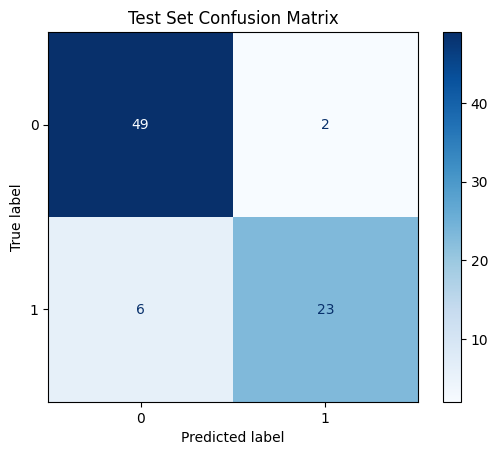

In [6]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]
accuracy = accuracy_score(y_test, y_pred)
print(f'Test accuracy: {accuracy:.2%}')
print('Confusion matrix:\n', confusion_matrix(y_test, y_pred))
print('Classification report:\n', classification_report(y_test, y_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')
plt.title('Test Set Confusion Matrix')
plt.show()

### Step 7: Visualization of Decision Regions

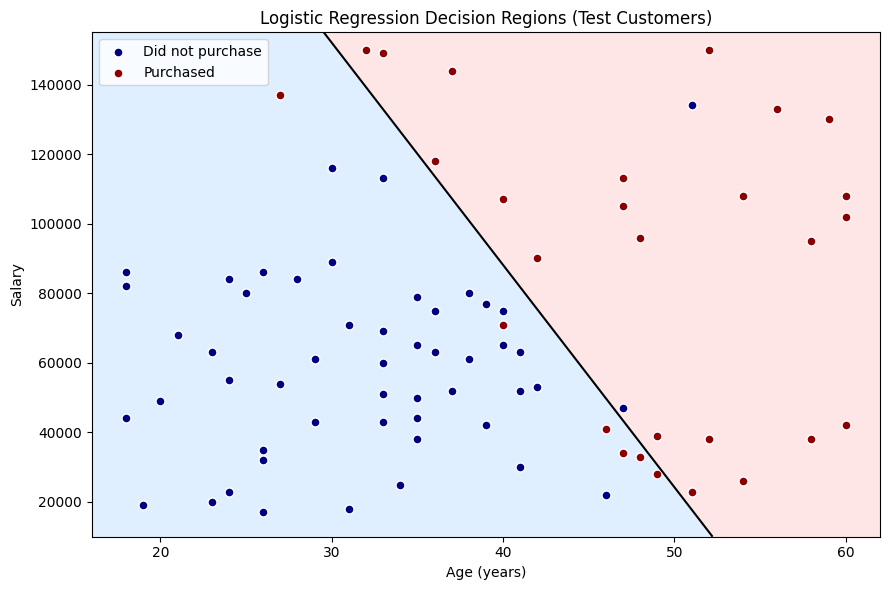

In [7]:
# Plot model decision regions in ORIGINAL Age and Salary units.
ages = np.linspace(X['Age'].min() - 2, X['Age'].max() + 2, 240)
salaries = np.linspace(X['Salary'].min() - 5000, X['Salary'].max() + 5000, 240)
xx, yy = np.meshgrid(ages, salaries)
mesh_df = pd.DataFrame({'Age': xx.ravel(), 'Salary': yy.ravel()})
mesh_scaled = scaler.transform(mesh_df)
prob_grid = model.predict_proba(mesh_scaled)[:, 1].reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, prob_grid, levels=[0, 0.5, 1], colors=['#cce5ff', '#ffd6d6'], alpha=0.6)
plt.contour(xx, yy, prob_grid, levels=[0.5], colors='black', linewidths=1.5)
for cls, label, color in [(0, 'Did not purchase', 'navy'), (1, 'Purchased', 'darkred')]:
    mask = y_test.to_numpy() == cls
    plt.scatter(X_test.iloc[mask]['Age'], X_test.iloc[mask]['Salary'],
                c=color, label=label, edgecolors='white', s=42)
plt.xlabel('Age (years)')
plt.ylabel('Salary')
plt.title('Logistic Regression Decision Regions (Test Customers)')
plt.legend()
plt.tight_layout()
plt.show()

## IV. Reflection Questions
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


### Reflection Answers

1. **Why probabilities can be used for classification:** Logistic regression estimates the probability that `Purchased = 1`. With the usual threshold of 0.50, probabilities at least 0.50 are classified as a purchase (1), and smaller probabilities as no purchase (0). This converts a continuous probability into a binary decision.

2. **Who is more likely to purchase:** The fitted model has positive coefficients for both standardized Age and Salary, so, holding the other predictor constant, older customers and customers with higher salaries have higher predicted purchase probabilities. This is an association in this dataset, not proof of causation.

3. **Possible causes of low accuracy:** Age and Salary do not capture all purchasing motivations. Customer preferences, existing vehicle ownership, financing options, and the timing of a purchase may matter. Overlap between buyers and nonbuyers, noisy records, class imbalance, and differences between training and testing samples can also reduce performance. Accuracy alone may obscure errors in a minority class.

4. **Potential improvements:** If available and ethically appropriate, test additional predictors such as prior vehicle ownership, vehicle needs, and financing eligibility. Check data quality and missing values, use cross-validation to assess stability, and tune logistic regression regularization with a training-only pipeline. Compare precision, recall, and confusion matrices alongside accuracy. Keep the final test set separate from model selection to avoid optimistic evaluation.